In [4]:
import pandas as pd
import numpy as np
import math
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
import glob
import time
import pybedtools
import subprocess as sp
%load_ext autoreload
%autoreload 2
%matplotlib inline
dpi = 150
matplotlib.rcParams['figure.dpi']= dpi
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams.update({'font.size': 12})
import pandas_extra
# from plot_utils import make_raincloud
from scipy import stats
from statsmodels.stats.multitest import multipletests
from scipy.stats import mannwhitneyu
import random
import tabix
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import warnings
warnings.filterwarnings('ignore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
"""Fix the directory where all figures will be saved"""

fdir = "../figures"
pe = pandas_extra.ExtraFunctions(fdir)
pe.makedirs(fdir)

In [ ]:
flist = glob.glob("../results/lmm_samp/*.tsv")
dlist = []
for f in flist:
    try:
        d = pd.read_csv(f, sep='\t')
        d['i'] = os.path.basename(f)
        dlist.append(d)
    except pd.errors.EmptyDataError:
        pass

In [15]:
x = pd.concat(dlist).dropna(subset="p_GLMMNB")
# print(x['i'].drop_duplicates())
x[['a', 'type', 'cluster']] = x['i'].map(lambda x: x.split(".HFPEF")[0]).str.split(".", expand=True) 
x.head()

3    coarse.clust.Endothelial.HFPEF:HFPEF-followup....
1      coarse.clust.NMJ.HFPEF:HFPEF-followup.19.16.tsv
1     sct.fine.Type_1s.HFPEF:HFPEF-followup.100.82.tsv
1    coarse.clust.Type_1.HFPEF:HFPEF-followup.200.1...
1    coarse.clust.Type_1.HFPEF:HFPEF-followup.200.1...
                           ...                        
1    coarse.clust.Endothelial.HFPEF:HFPEF-followup....
1    coarse.clust.Type_1.HFPEF:HFPEF-followup.200.2...
1     sct.fine.Type_1s.HFPEF:HFPEF-followup.100.74.tsv
1    coarse.clust.Endothelial.HFPEF:HFPEF-followup....
1    coarse.clust.Type_1.HFPEF:HFPEF-followup.200.1...
Name: i, Length: 1136, dtype: object


,index,group_i,estimate,se,z,p_GLMMNB,p_LRT,model,nsamp_hfpef,nsamp_hfpef.followup,i,a,type,cluster
3,chr9:15422503-15423004,groupHFPEF-followup,0.257044,0.117806,2.181929,0.029115,0.029466,random_individual,66,48,coarse.clust.Endothelial.HFPEF:HFPEF-followup....,coarse,clust,Endothelial
4,chr9:15422503-15423004,groupHFPEF-followup,0.257891,0.151767,1.699254,0.089271,0.089170,fixed_individual_paired,45,44,coarse.clust.Endothelial.HFPEF:HFPEF-followup....,coarse,clust,Endothelial
5,chr9:15510712-15511213,groupHFPEF-followup,0.007853,0.170543,0.046046,0.963274,NaN,random_individual,66,48,coarse.clust.Endothelial.HFPEF:HFPEF-followup....,coarse,clust,Endothelial
6,chr9:15510712-15511213,groupHFPEF-followup,0.100950,0.230419,0.438116,0.661302,NaN,fixed_individual_paired,45,44,coarse.clust.Endothelial.HFPEF:HFPEF-followup....,coarse,clust,Endothelial
7,chr9:15510177-15510678,groupHFPEF-followup,0.303225,0.256421,1.182529,0.236996,NaN,random_individual,66,48,coarse.clust.Endothelial.HFPEF:HFPEF-followup....,coarse,clust,Endothelial


In [44]:
x1 = x.pivot_table(index=["index", "type", "cluster"], columns = "model", values=["p_GLMMNB", "p_LRT"])
x1.columns = pe.flatten_multiindex(x1)
x1.head()

def logp(x):
    try:
        out = -math.log(x, 10)
    except:
        out = np.nan
    return out

# multiple testing and how many sig in each clust type
l = []
for (type, clust), grp in x1.reset_index().groupby(['type', 'cluster']):
    for c in [col for col in grp.columns if "p_" in col]:
        try:
            qlist = multipletests(grp.dropna(subset=c)[c], method="fdr_bh")[1]
        except:
            qlist = []
        l.append([type, clust, c, len([v for v in qlist if v<0.05])])  
        # print(f"{type} {clust} N sig after mult.test len([v for v in qlist if v<0.05])"
n = pd.DataFrame(l)
# x1.fillna(1, inplace=True)

# plot -logp to compare. 
x1.fillna(1, inplace=True)

for c in x1.columns:
    x1[c] = x1[c].map(logp)
x1.reset_index(inplace=True)
x1.head()

,index,type,cluster,p_GLMMNB_fixed_individual_paired,p_GLMMNB_random_individual,p_LRT_fixed_individual_paired,p_LRT_random_individual
0,chr10:100009156-100009657,clust,Endothelial,0.108875,0.694180,0.108993,0.702739
1,chr10:100009156-100009657,clust,FAP,-0.000000,0.069832,-0.000000,0.069910
2,chr10:100009156-100009657,clust,Immune,-0.000000,0.074113,-0.000000,0.074446
3,chr10:100009156-100009657,clust,NMJ,-0.000000,0.302964,-0.000000,0.302431
4,chr10:100009156-100009657,clust,Neuronal,-0.000000,0.995427,-0.000000,0.979337


In [46]:
n.sort_values([3], ascending=False)

,0,1,2,3
38,clust,Type_2,p_LRT_fixed_individual_paired,91
34,clust,Type_1,p_LRT_fixed_individual_paired,60
32,clust,Type_1,p_GLMMNB_fixed_individual_paired,30
36,clust,Type_2,p_GLMMNB_fixed_individual_paired,23
74,fine,Type_2a,p_LRT_fixed_individual_paired,23
...,...,...,...,...
3,clust,Adipocyte,p_LRT_random_individual,0
1,clust,Adipocyte,p_GLMMNB_random_individual,0
0,clust,Adipocyte,p_GLMMNB_fixed_individual_paired,0
40,fine,Macrophages,p_GLMMNB_fixed_individual_paired,0


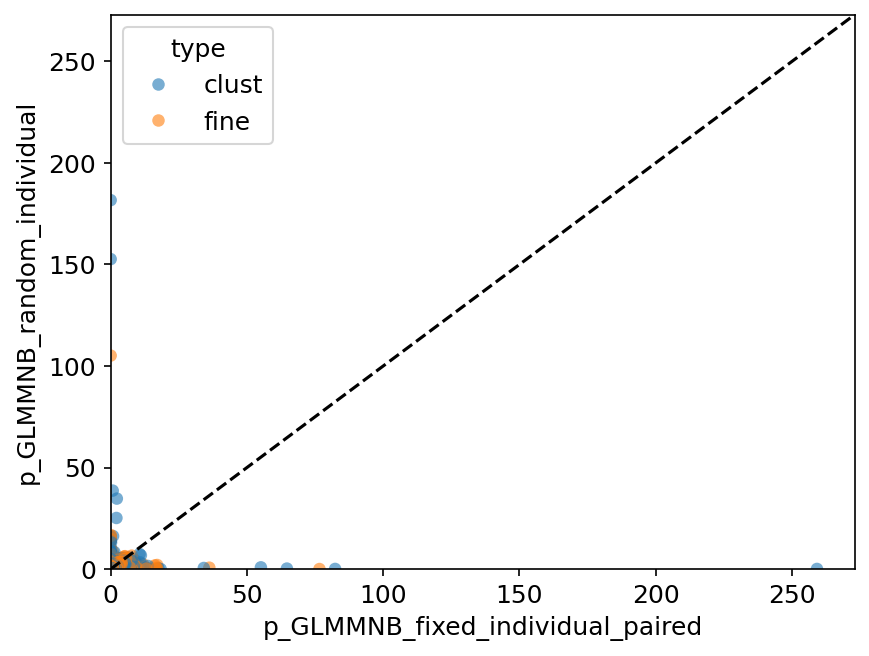

In [47]:
g = sns.scatterplot(data=x1, x="p_GLMMNB_fixed_individual_paired", y="p_GLMMNB_random_individual", hue="type", **{'alpha':0.6, 'linewidth':0})
pe.symmetric_scatter(g)

In [ ]:
## Paired design with fixed individual effect is better than random design.

In [49]:
n[n[2]=='p_LRT_fixed_individual_paired'].sort_values([3], ascending=False)

,0,1,2,3
38,clust,Type_2,p_LRT_fixed_individual_paired,91
34,clust,Type_1,p_LRT_fixed_individual_paired,60
74,fine,Type_2a,p_LRT_fixed_individual_paired,23
62,fine,Type_1s,p_LRT_fixed_individual_paired,10
30,clust,Smooth_muscle,p_LRT_fixed_individual_paired,8
78,fine,Type_2x,p_LRT_fixed_individual_paired,6
58,fine,Type_1,p_LRT_fixed_individual_paired,6
14,clust,Immune,p_LRT_fixed_individual_paired,5
26,clust,Satellite,p_LRT_fixed_individual_paired,4
46,fine,Pericytes,p_LRT_fixed_individual_paired,4


In [51]:
flist1 = glob.glob("../results/lmm/*.tsv")
dlist = []
for f in flist1:
    try:
        d = pd.read_csv(f, sep='\t')
        d['i'] = os.path.basename(f)
        dlist.append(d)
    except pd.errors.EmptyDataError:
        pass

y = pd.concat(dlist).dropna(subset="p_GLMMNB")
# print(x['i'].drop_duplicates())
y[['a', 'type', 'cluster']] = y['i'].map(lambda x: x.split(".No-HFPEF")[0]).str.split(".", expand=True) 
y.head()

,index,group_i,estimate,se,z,p_GLMMNB,p_LRT,i,a,type,cluster
1,chr17:17641743-17642244,groupNo-HFPEF,-0.257201,0.156652,-1.641863,0.100618,0.094082,sct.fine.Type_2x.No-HFPEF:HFPEF.100.40.tsv,sct,fine,Type_2x
3,chr17:17681089-17681590,groupNo-HFPEF,-0.082162,0.069834,-1.176536,0.239381,0.236968,sct.fine.Type_2x.No-HFPEF:HFPEF.100.40.tsv,sct,fine,Type_2x
4,chr17:17682658-17683159,groupNo-HFPEF,-0.096603,0.123552,-0.781883,0.434283,0.432573,sct.fine.Type_2x.No-HFPEF:HFPEF.100.40.tsv,sct,fine,Type_2x
5,chr17:17682118-17682619,groupNo-HFPEF,0.008566,0.112172,0.076368,0.939127,0.939157,sct.fine.Type_2x.No-HFPEF:HFPEF.100.40.tsv,sct,fine,Type_2x
6,chr17:17681592-17682093,groupNo-HFPEF,-0.035810,0.094444,-0.379169,0.704563,0.703869,sct.fine.Type_2x.No-HFPEF:HFPEF.100.40.tsv,sct,fine,Type_2x


In [55]:
l1 = []
for (type, clust), grp in y.reset_index().groupby(['type', 'cluster']):
    for c in [col for col in grp.columns if "p_" in col]:
        try:
            qlist = multipletests(grp.dropna(subset=c)[c], method="fdr_bh")[1]
        except:
            qlist = []
        l1.append([type, clust, c, len([v for v in qlist if v<0.05])])  
        # print(f"{type} {clust} N sig after mult.test len([v for v in qlist if v<0.05])"
n1 = pd.DataFrame(l1)
n1[n1[2]=='p_GLMMNB'].sort_values([3], ascending=False)

,0,1,2,3
25,clust,Type_1,p_GLMMNB,4419
43,fine,Type_1,p_GLMMNB,4028
28,clust,Type_2,p_GLMMNB,1085
55,fine,Type_2a,p_GLMMNB,618
46,fine,Type_1s,p_GLMMNB,174
58,fine,Type_2x,p_GLMMNB,67
4,clust,Endothelial,p_GLMMNB,24
13,clust,NMJ,p_GLMMNB,22
7,clust,FAP,p_GLMMNB,21
34,fine,Pericytes,p_GLMMNB,16


In [56]:
n1[n1[2]=='p_LRT'].sort_values([3], ascending=False)

,0,1,2,3
26,clust,Type_1,p_LRT,3511
44,fine,Type_1,p_LRT,3207
29,clust,Type_2,p_LRT,693
56,fine,Type_2a,p_LRT,425
47,fine,Type_1s,p_LRT,29
59,fine,Type_2x,p_LRT,12
32,fine,Macrophages,p_LRT,12
14,clust,NMJ,p_LRT,11
53,fine,Type_2_GALNTL6,p_LRT,11
11,clust,Immune,p_LRT,10
